In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters, measure, morphology
import scipy.ndimage as ndi

print("ready")

Matplotlib is building the font cache; this may take a moment.


ready


In [2]:
img = data.human_mitosis()  # grayscale cell image, stand-in for stained tissue
plt.figure(figsize=(6,6))
plt.imshow(img, cmap="gray")
plt.title("Placeholder image (not real cerebellar tissue)")
plt.axis("off")
plt.show()

ModuleNotFoundError: The requested file is part of the scikit-image distribution, but requires the installation of an optional dependency, pooch. To install pooch, use your preferred python package manager. Follow installation instruction found at https://scikit-image.org/docs/stable/user_guide/install.html

In [3]:
%pip install pooch

Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters, measure, morphology
import scipy.ndimage as ndi

print("ready")

ready


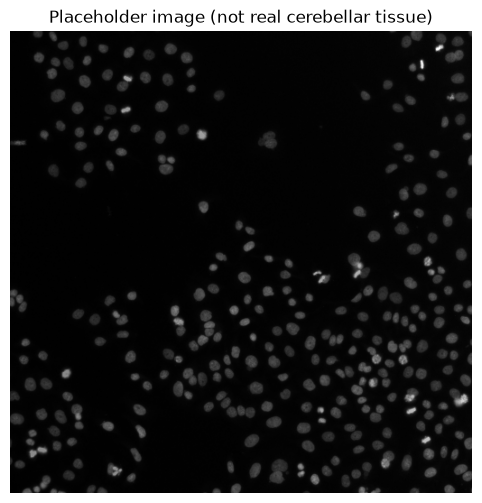

In [2]:
img = data.human_mitosis()
plt.figure(figsize=(6,6))
plt.imshow(img, cmap="gray")
plt.title("Placeholder image (not real cerebellar tissue)")
plt.axis("off")
plt.show()

In [5]:
import os
print(os.getcwd())
print(os.listdir())


/Users/georgerivera/cerebellar-thickness
['Untitled.ipynb', '01_explore.ipynb', 'README.md', '.gitignore', '.virtual_documents', '.ipynb_checkpoints', '.git', 'notebooks']


In [4]:
from skimage import io

cerebellum = io.imread("data/100149965_1983.jpg")
print(cerebellum.shape, cerebellum.dtype)

plt.figure(figsize=(8,8))
plt.imshow(cerebellum)
plt.title("Allen Human Brain Atlas — downloaded section")
plt.axis("off")
plt.show()

(543, 551, 3) uint8


NameError: name 'plt' is not defined

In [3]:
import os
print(os.getcwd())
print(os.listdir())

/Users/georgerivera/cerebellar-thickness/notebooks
['.gitkeep', '01_explore.ipynb', '.ipynb_checkpoints']


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters, measure, morphology, io
import scipy.ndimage as ndi

print("ready")


ready


(543, 551, 3) uint8


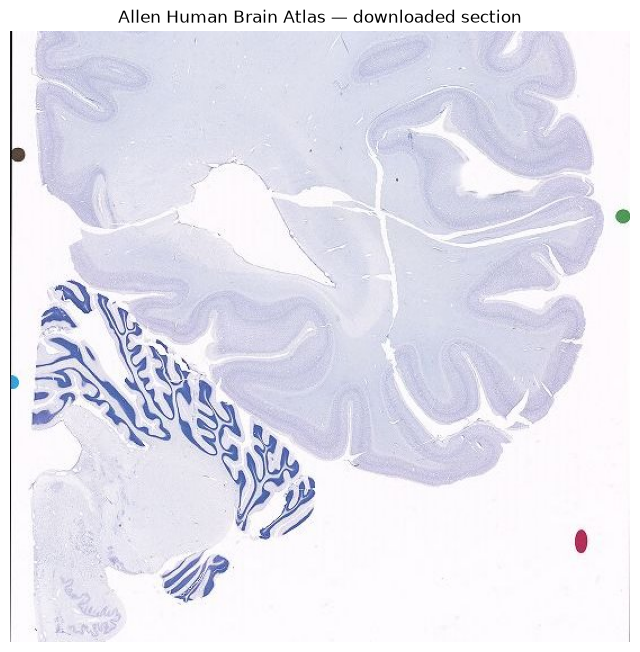

In [6]:
cerebellum = io.imread("data/100149965_1983.jpg")
print(cerebellum.shape, cerebellum.dtype)

plt.figure(figsize=(8,8))
plt.imshow(cerebellum)
plt.title("Allen Human Brain Atlas — downloaded section")
plt.axis("off")
plt.show()

(543, 551) float64 0.0008333333333333333 1.0


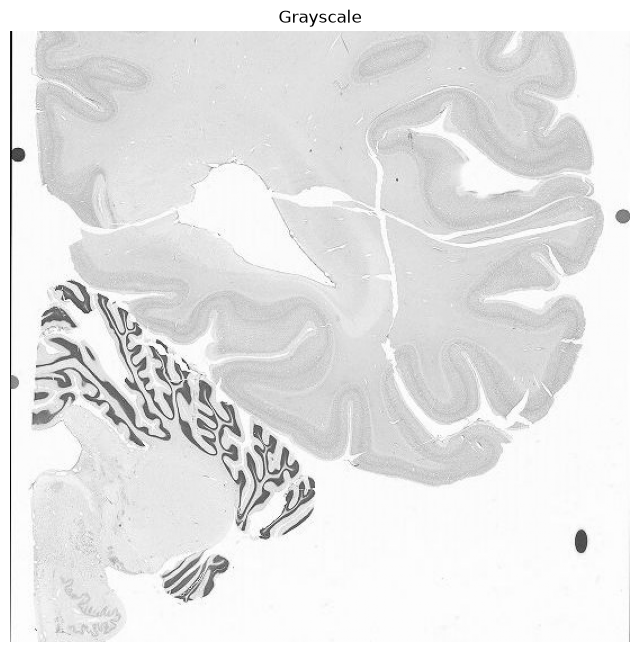

In [7]:
from skimage.color import rgb2gray

gray = rgb2gray(cerebellum)
print(gray.shape, gray.dtype, gray.min(), gray.max())

plt.figure(figsize=(8,8))
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")
plt.show()

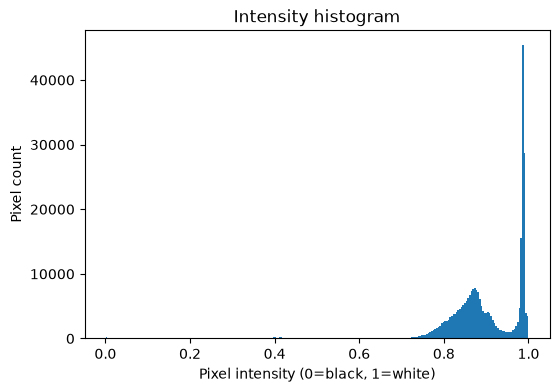

In [8]:
plt.figure(figsize=(6,4))
plt.hist(gray.ravel(), bins=256)
plt.title("Intensity histogram")
plt.xlabel("Pixel intensity (0=black, 1=white)")
plt.ylabel("Pixel count")
plt.show()

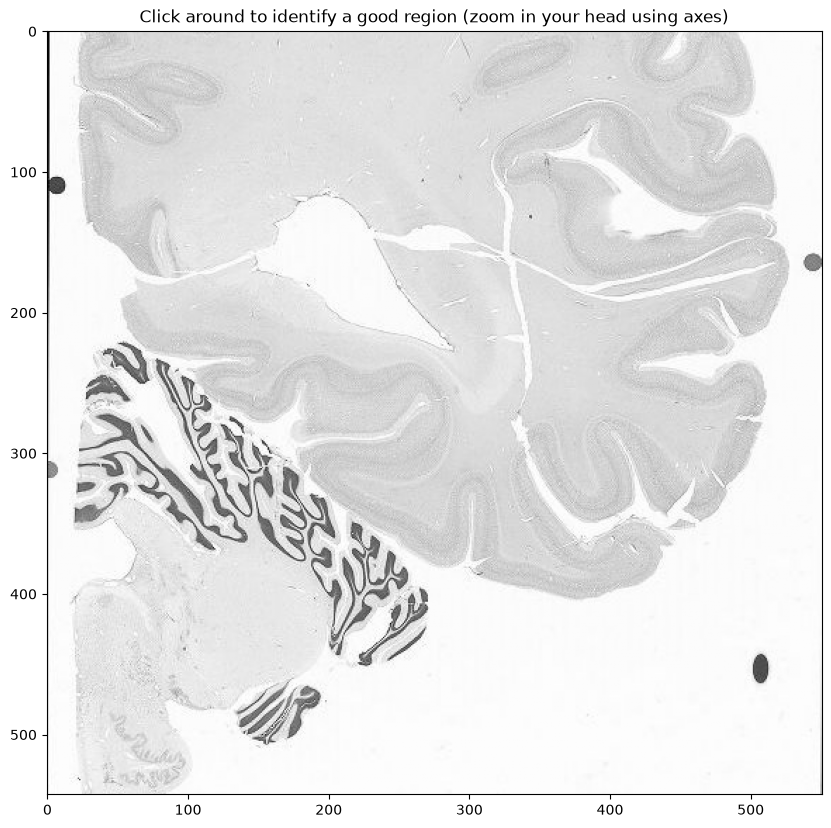

In [9]:
plt.figure(figsize=(10,10))
plt.imshow(gray, cmap="gray")
plt.title("Click around to identify a good region (zoom in your head using axes)")
plt.show()

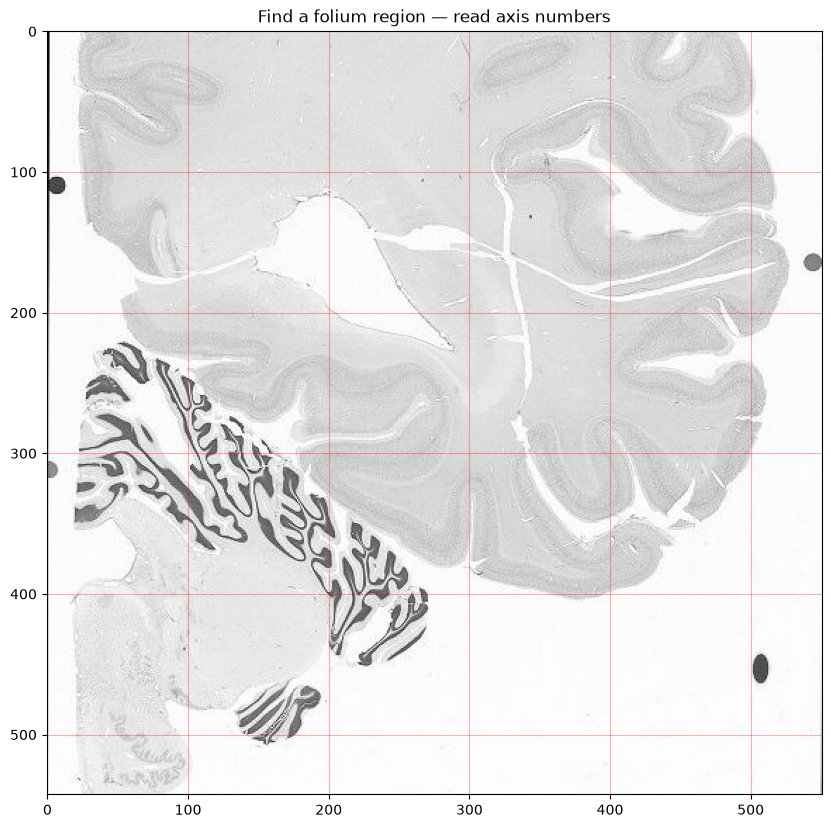

In [10]:
plt.figure(figsize=(10,10))
plt.imshow(gray, cmap="gray")
plt.title("Find a folium region — read axis numbers")
plt.grid(color='red', alpha=0.3)
plt.show()

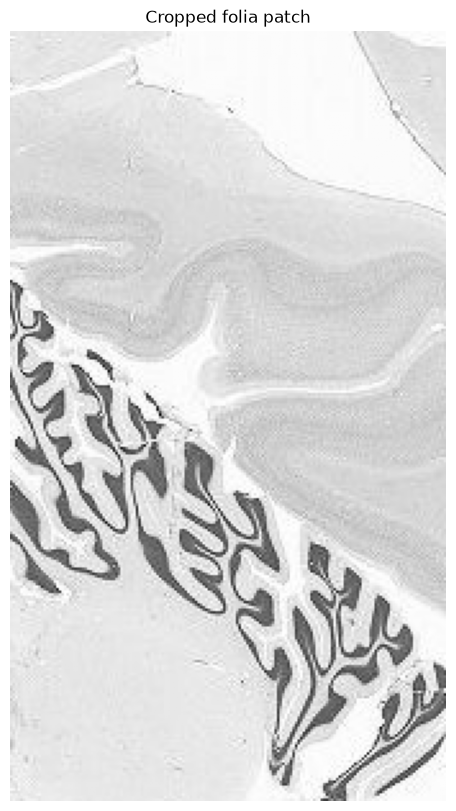

In [12]:
patch = gray[150:450, 100:270]

plt.figure(figsize=(8,10))
plt.imshow(patch, cmap="gray")
plt.title("Cropped folia patch")
plt.axis("off")
plt.show()

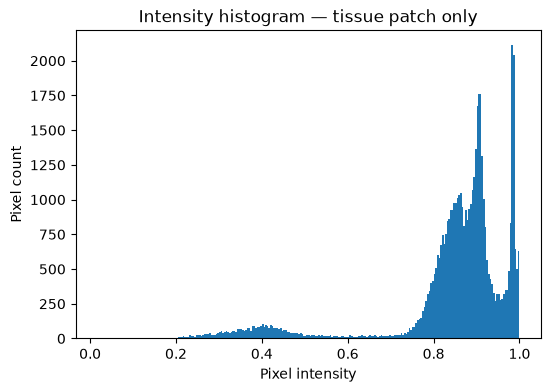

In [13]:
plt.figure(figsize=(6,4))
plt.hist(patch.ravel(), bins=256)
plt.title("Intensity histogram — tissue patch only")
plt.xlabel("Pixel intensity")
plt.ylabel("Pixel count")
plt.show()

Thresholds: [0.61350376 0.88270512]


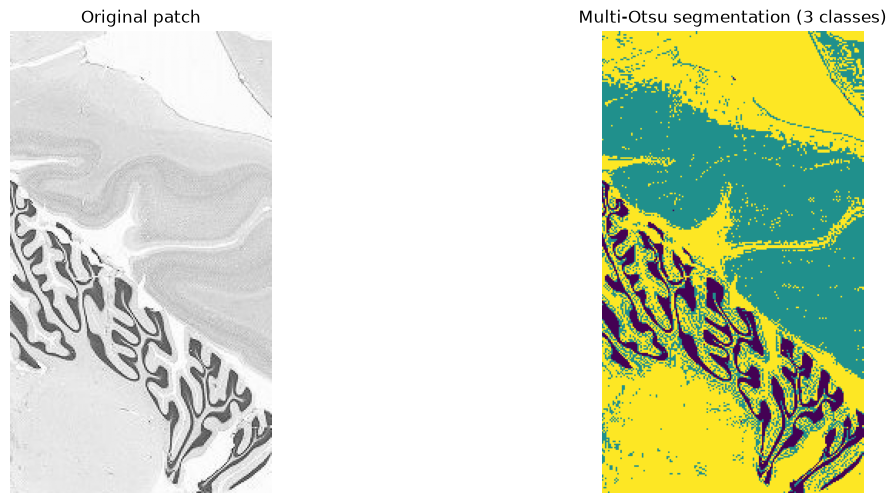

In [14]:
from skimage.filters import threshold_multiotsu

# Try 3 classes first: background, molecular layer, granular layer
thresholds = threshold_multiotsu(patch, classes=3)
print("Thresholds:", thresholds)

regions = np.digitize(patch, bins=thresholds)

plt.figure(figsize=(14,6))

plt.subplot(1,2,1)
plt.imshow(patch, cmap="gray")
plt.title("Original patch")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(regions, cmap="viridis")
plt.title("Multi-Otsu segmentation (3 classes)")
plt.axis("off")

plt.show()

/var/folders/gh/drjz5j_j7zb9cl9z206669bc0000gn/T/ipykernel_14204/3532420572.py:7: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  granular_clean = morphology.remove_small_objects(granular, min_size=20)
/var/folders/gh/drjz5j_j7zb9cl9z206669bc0000gn/T/ipykernel_14204/3532420572.py:8: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only remove

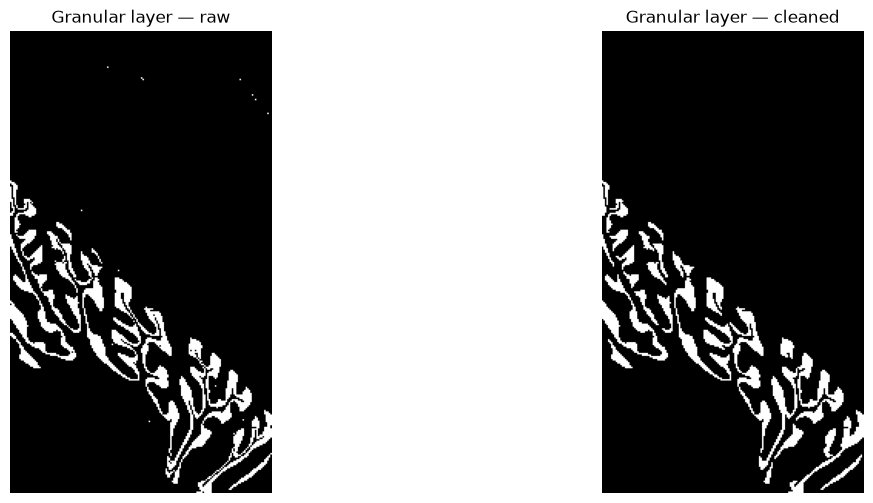

In [15]:
from skimage import morphology

# Isolate the granular layer (darkest class = 0)
granular = regions == 0

# Remove small speckle noise
granular_clean = morphology.remove_small_objects(granular, min_size=20)
granular_clean = morphology.remove_small_holes(granular_clean, area_threshold=20)

plt.figure(figsize=(14,6))

plt.subplot(1,2,1)
plt.imshow(granular, cmap="gray")
plt.title("Granular layer — raw")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(granular_clean, cmap="gray")
plt.title("Granular layer — cleaned")
plt.axis("off")

plt.show()

In [ ]:
Thickness measurement

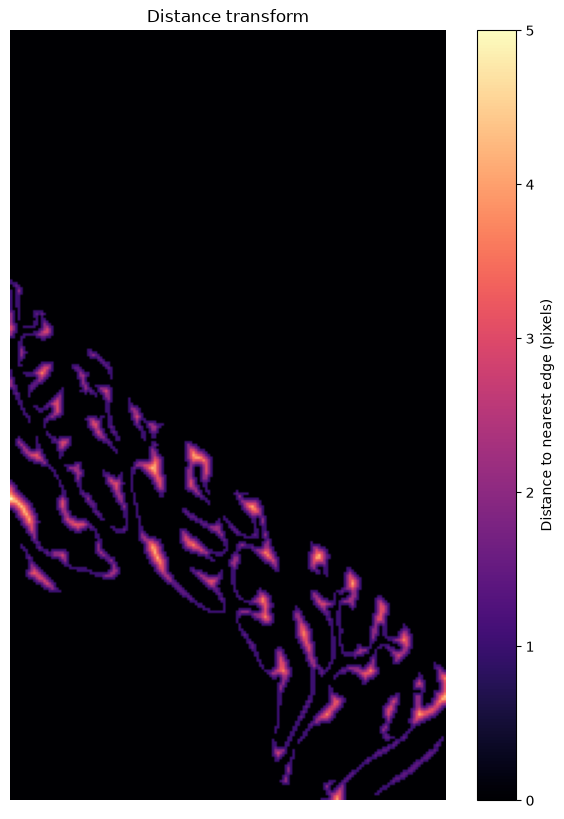

In [16]:
from scipy import ndimage as ndi

distance = ndi.distance_transform_edt(granular_clean)

plt.figure(figsize=(8,10))
plt.imshow(distance, cmap="magma")
plt.colorbar(label="Distance to nearest edge (pixels)")
plt.title("Distance transform")
plt.axis("off")
plt.show()

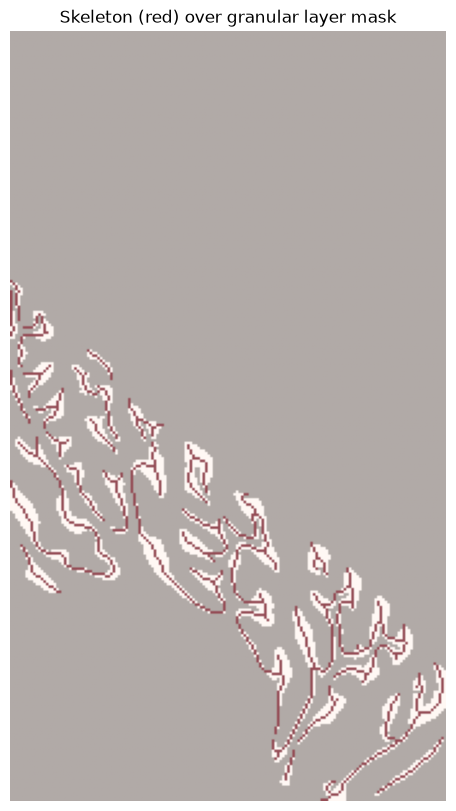

In [17]:
from skimage.morphology import skeletonize

skeleton = skeletonize(granular_clean)

plt.figure(figsize=(8,10))
plt.imshow(granular_clean, cmap="gray")
plt.imshow(skeleton, cmap="Reds", alpha=0.7)
plt.title("Skeleton (red) over granular layer mask")
plt.axis("off")
plt.show()

Number of skeleton points: 1258
Mean thickness (pixels): 3.3812615712140484
Median thickness (pixels): 2.8284271247461903
Std dev (pixels): 1.5952468885291042


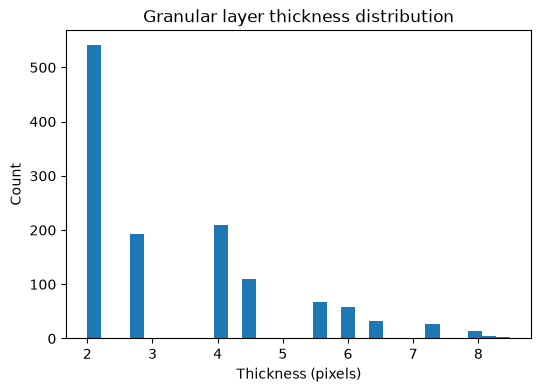

In [18]:
thickness_values = distance[skeleton] * 2   # diameter = 2 * radius

print("Number of skeleton points:", len(thickness_values))
print("Mean thickness (pixels):", thickness_values.mean())
print("Median thickness (pixels):", np.median(thickness_values))
print("Std dev (pixels):", thickness_values.std())

plt.figure(figsize=(6,4))
plt.hist(thickness_values, bins=30)
plt.xlabel("Thickness (pixels)")
plt.ylabel("Count")
plt.title("Granular layer thickness distribution")
plt.show()

(3185, 2229, 3)


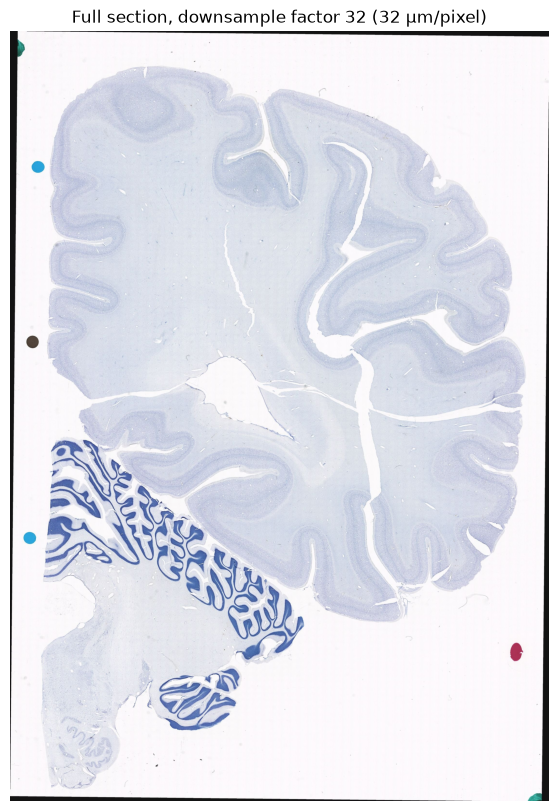

In [19]:
cerebellum_calibrated = io.imread("data/100149965_full_ds32.jpg")
print(cerebellum_calibrated.shape)

plt.figure(figsize=(10,10))
plt.imshow(cerebellum_calibrated, cmap="gray" if cerebellum_calibrated.ndim==2 else None)
plt.title("Full section, downsample factor 32 (32 µm/pixel)")
plt.axis("off")
plt.show()

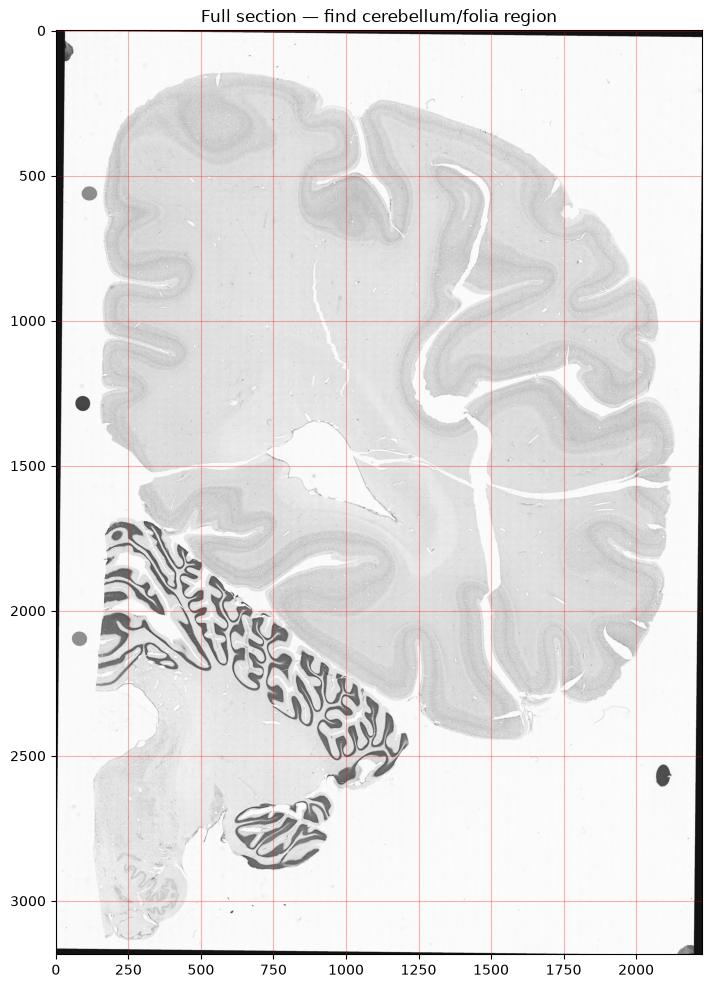

In [20]:
gray_cal = rgb2gray(cerebellum_calibrated)

plt.figure(figsize=(12,12))
plt.imshow(gray_cal, cmap="gray")
plt.title("Full section — find cerebellum/folia region")
plt.grid(color='red', alpha=0.3)
plt.show()

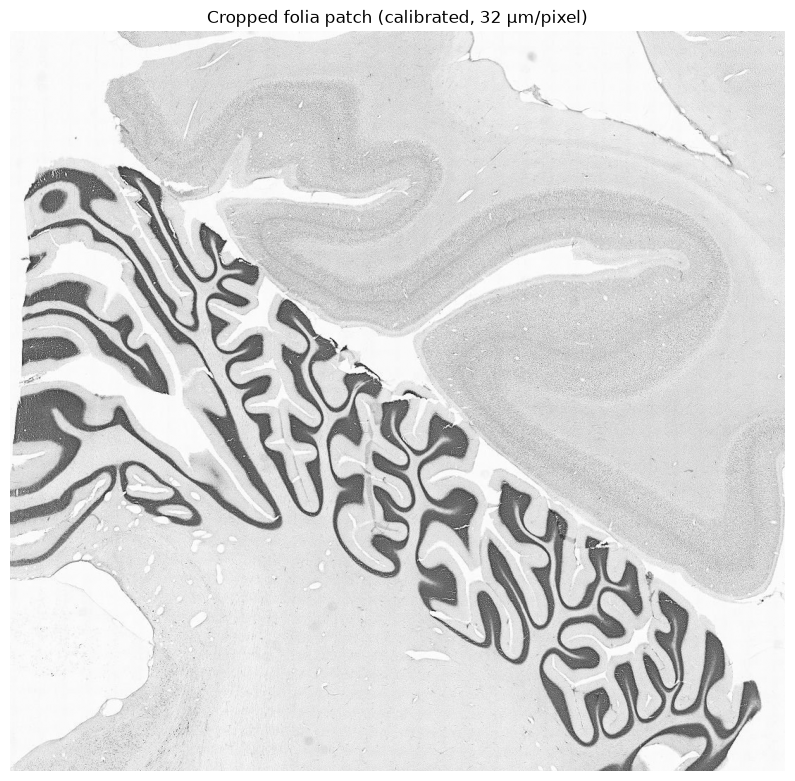

In [22]:
patch_cal = gray_cal[1500:2550, 150:1250]

plt.figure(figsize=(10,12))
plt.imshow(patch_cal, cmap="gray")
plt.title("Cropped folia patch (calibrated, 32 µm/pixel)")
plt.axis("off")
plt.show()

Thresholds: [0.59820311 0.86218561]


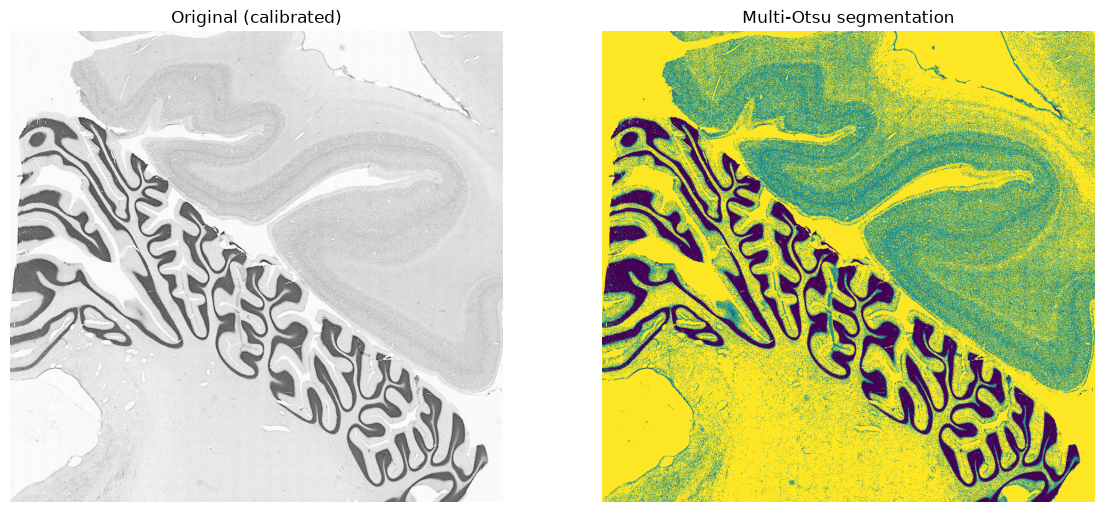

In [23]:
thresholds_cal = threshold_multiotsu(patch_cal, classes=3)
print("Thresholds:", thresholds_cal)

regions_cal = np.digitize(patch_cal, bins=thresholds_cal)

plt.figure(figsize=(14,8))
plt.subplot(1,2,1)
plt.imshow(patch_cal, cmap="gray")
plt.title("Original (calibrated)")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(regions_cal, cmap="viridis")
plt.title("Multi-Otsu segmentation")
plt.axis("off")
plt.show()

/var/folders/gh/drjz5j_j7zb9cl9z206669bc0000gn/T/ipykernel_14204/1293587404.py:3: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  granular_cal_clean = morphology.remove_small_objects(granular_cal, min_size=20)
/var/folders/gh/drjz5j_j7zb9cl9z206669bc0000gn/T/ipykernel_14204/1293587404.py:4: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter onl

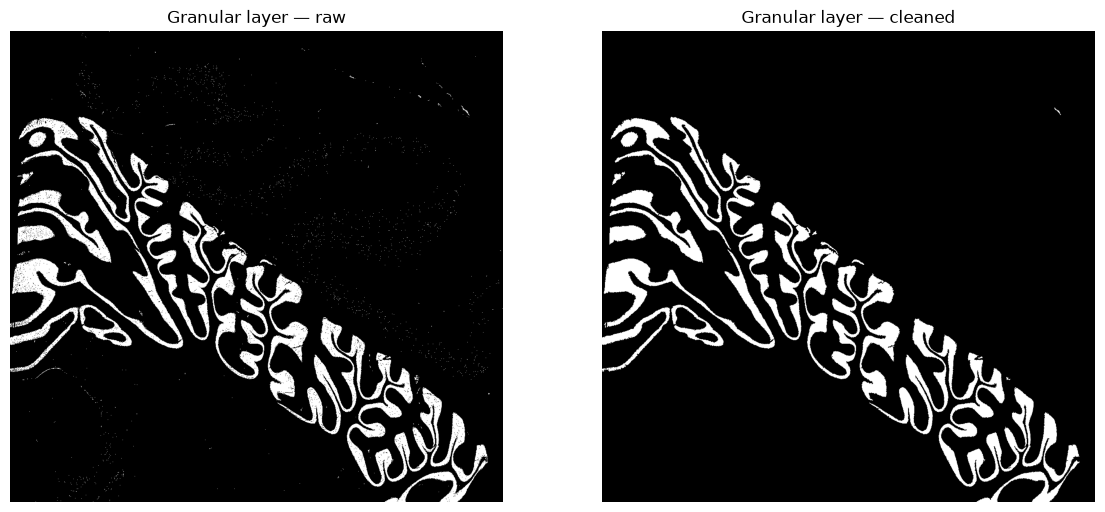

In [24]:
granular_cal = regions_cal == 0

granular_cal_clean = morphology.remove_small_objects(granular_cal, min_size=20)
granular_cal_clean = morphology.remove_small_holes(granular_cal_clean, area_threshold=20)

plt.figure(figsize=(14,8))
plt.subplot(1,2,1)
plt.imshow(granular_cal, cmap="gray")
plt.title("Granular layer — raw")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(granular_cal_clean, cmap="gray")
plt.title("Granular layer — cleaned")
plt.axis("off")
plt.show()

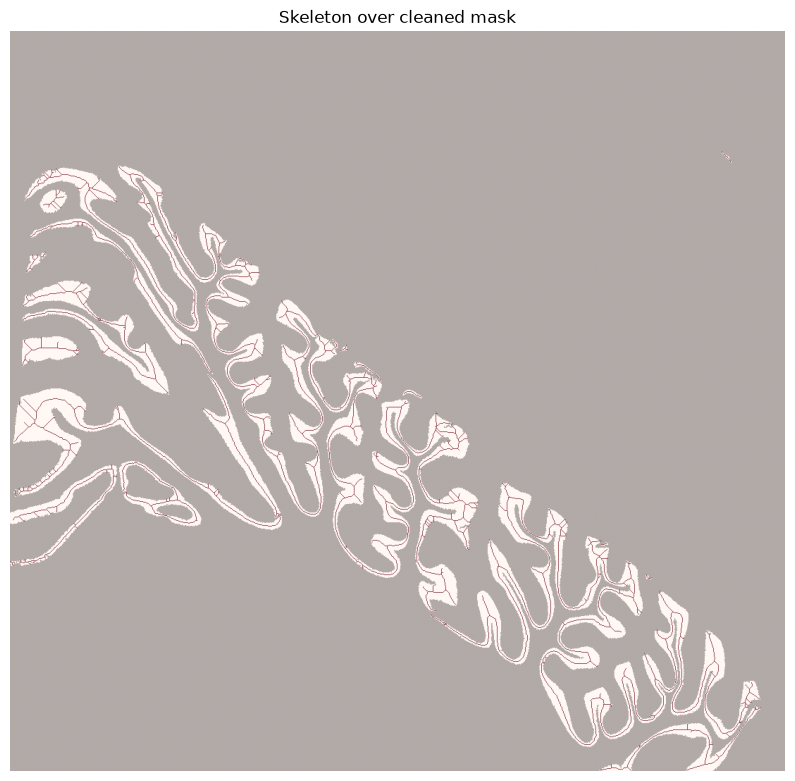

In [25]:
distance_cal = ndi.distance_transform_edt(granular_cal_clean)
skeleton_cal = skeletonize(granular_cal_clean)

plt.figure(figsize=(10,12))
plt.imshow(granular_cal_clean, cmap="gray")
plt.imshow(skeleton_cal, cmap="Reds", alpha=0.7)
plt.title("Skeleton over cleaned mask")
plt.axis("off")
plt.show()

Number of skeleton points: 10924
Mean thickness (µm): 333.6665278931194
Median thickness (µm): 271.5290039756342
Std dev (µm): 216.85119870160648


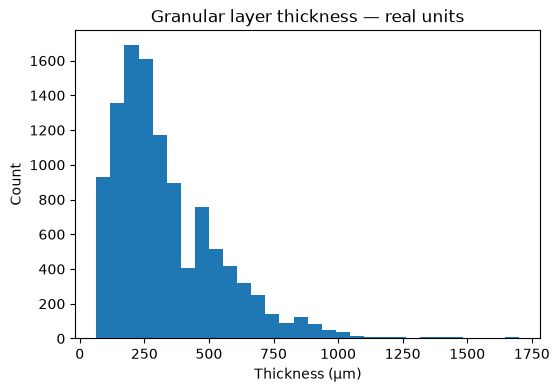

In [26]:
MICRONS_PER_PIXEL = 32

thickness_px = distance_cal[skeleton_cal] * 2
thickness_um = thickness_px * MICRONS_PER_PIXEL

print("Number of skeleton points:", len(thickness_um))
print("Mean thickness (µm):", thickness_um.mean())
print("Median thickness (µm):", np.median(thickness_um))
print("Std dev (µm):", thickness_um.std())

plt.figure(figsize=(6,4))
plt.hist(thickness_um, bins=30)
plt.xlabel("Thickness (µm)")
plt.ylabel("Count")
plt.title("Granular layer thickness — real units")
plt.show()

In [27]:
from skimage import img_as_ubyte
io.imsave("data/patch_cal_for_fiji.png", img_as_ubyte(patch_cal))
print("saved")

saved


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters, measure, morphology, io
import scipy.ndimage as ndi
from skimage.color import rgb2gray
from skimage.filters import threshold_multiotsu
from skimage.morphology import skeletonize

print("ready")

ready


In [6]:
manual_thickness_px = [16.964, 8.911, 17.341, 7.674, 5.888, 9.390, 15.710, 10.382, 29.790, 15.715]

MICRONS_PER_PIXEL = 32
manual_thickness_um = [v * MICRONS_PER_PIXEL for v in manual_thickness_px]

print("Manual mean (µm):", np.mean(manual_thickness_um))
print("Manual median (µm):", np.median(manual_thickness_um))
print("Manual std (µm):", np.std(manual_thickness_um))
print()
for i, (px, um) in enumerate(zip(manual_thickness_px, manual_thickness_um), start=1):
    print(f"{i}: {px:.2f} px -> {um:.1f} µm")

Manual mean (µm): 440.84799999999996
Manual median (µm): 417.472
Manual std (µm): 212.4328247630295

1: 16.96 px -> 542.8 µm
2: 8.91 px -> 285.2 µm
3: 17.34 px -> 554.9 µm
4: 7.67 px -> 245.6 µm
5: 5.89 px -> 188.4 µm
6: 9.39 px -> 300.5 µm
7: 15.71 px -> 502.7 µm
8: 10.38 px -> 332.2 µm
9: 29.79 px -> 953.3 µm
10: 15.71 px -> 502.9 µm


1: manual=  542.8  auto=  288.0  diff= +254.8
2: manual=  285.2  auto=  320.0  diff=  -34.8
3: manual=  554.9  auto=  512.0  diff=  +42.9
4: manual=  245.6  auto=  256.0  diff=  -10.4
5: manual=  188.4  auto=  128.0  diff=  +60.4
6: manual=  300.5  auto=  352.0  diff=  -51.5
7: manual=  502.7  auto=  416.0  diff=  +86.7
8: manual=  332.2  auto=  288.0  diff=  +44.2
9: manual=  953.3  auto=  896.0  diff=  +57.3
10: manual=  502.9  auto=  416.0  diff=  +86.9

Mean absolute error: 73.0 µm
Bias (manual − auto): 53.6 µm
95% limits of agreement: -114.1 to 221.4 µm
Correlation (r): 0.924


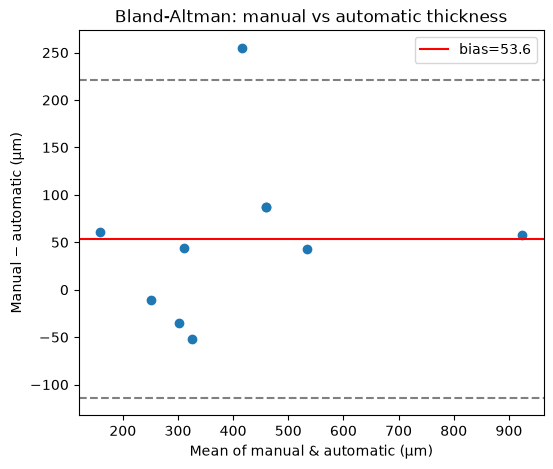

In [7]:
# Automatic measurement at the exact same 10 locations used for manual measurement
auto_thickness_um = [288.0, 320.0, 512.0, 256.0, 128.0, 352.0, 416.0, 288.0, 896.0, 416.0]

diff = np.array(manual_thickness_um) - np.array(auto_thickness_um)
mae = np.mean(np.abs(diff))
bias = np.mean(diff)
sd_diff = np.std(diff, ddof=1)
loa_low, loa_high = bias - 1.96*sd_diff, bias + 1.96*sd_diff
r = np.corrcoef(manual_thickness_um, auto_thickness_um)[0,1]

for i, (m, a, d) in enumerate(zip(manual_thickness_um, auto_thickness_um, diff), start=1):
    print(f"{i}: manual={m:7.1f}  auto={a:7.1f}  diff={d:+7.1f}")

print()
print(f"Mean absolute error: {mae:.1f} µm")
print(f"Bias (manual − auto): {bias:.1f} µm")
print(f"95% limits of agreement: {loa_low:.1f} to {loa_high:.1f} µm")
print(f"Correlation (r): {r:.3f}")

plt.figure(figsize=(6,5))
mean_vals = (np.array(manual_thickness_um)+np.array(auto_thickness_um))/2
plt.scatter(mean_vals, diff)
plt.axhline(bias, color='red', label=f'bias={bias:.1f}')
plt.axhline(loa_low, color='gray', linestyle='--')
plt.axhline(loa_high, color='gray', linestyle='--')
plt.xlabel("Mean of manual & automatic (µm)")
plt.ylabel("Manual − automatic (µm)")
plt.title("Bland-Altman: manual vs automatic thickness")
plt.legend()
plt.show()

In [9]:
def measure_thickness(patch, n_classes=3, min_size=20, area_threshold=20):
    thresholds = threshold_multiotsu(patch, classes=n_classes)
    regions = np.digitize(patch, bins=thresholds)
    granular = regions == 0  # darkest class

    granular_clean = morphology.remove_small_objects(granular, min_size=min_size)
    granular_clean = morphology.remove_small_holes(granular_clean, area_threshold=area_threshold)

    distance = ndi.distance_transform_edt(granular_clean)
    skeleton = skeletonize(granular_clean)

    thickness_px = distance[skeleton] * 2
    thickness_um = thickness_px * MICRONS_PER_PIXEL
    return thickness_um

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, morphology
from skimage.color import rgb2gray
from skimage.filters import threshold_multiotsu
from skimage.morphology import skeletonize
import scipy.ndimage as ndi

MICRONS_PER_PIXEL = 32

# Load the calibrated full-section image and convert to grayscale
cerebellum_calibrated = io.imread("data/100149965_full_ds32.jpg")
gray_cal = rgb2gray(cerebellum_calibrated)

# Crop to the folia patch
patch_cal = gray_cal[1500:2550, 150:1250]

print("patch_cal shape:", patch_cal.shape)
print("ready")

patch_cal shape: (1050, 1100)
ready


/var/folders/gh/drjz5j_j7zb9cl9z206669bc0000gn/T/ipykernel_1396/2110472840.py:6: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  granular_clean = morphology.remove_small_objects(granular, min_size=min_size)
/var/folders/gh/drjz5j_j7zb9cl9z206669bc0000gn/T/ipykernel_1396/2110472840.py:7: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only re

min_size=  5: mean thickness = 321.7 µm  (n=11554 points)
min_size= 10: mean thickness = 329.5 µm  (n=11107 points)


/var/folders/gh/drjz5j_j7zb9cl9z206669bc0000gn/T/ipykernel_1396/2110472840.py:6: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  granular_clean = morphology.remove_small_objects(granular, min_size=min_size)
/var/folders/gh/drjz5j_j7zb9cl9z206669bc0000gn/T/ipykernel_1396/2110472840.py:7: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only re

min_size= 20: mean thickness = 333.7 µm  (n=10924 points)
min_size= 40: mean thickness = 335.8 µm  (n=10824 points)
min_size= 80: mean thickness = 337.1 µm  (n=10767 points)


/var/folders/gh/drjz5j_j7zb9cl9z206669bc0000gn/T/ipykernel_1396/2110472840.py:6: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  granular_clean = morphology.remove_small_objects(granular, min_size=min_size)
/var/folders/gh/drjz5j_j7zb9cl9z206669bc0000gn/T/ipykernel_1396/2110472840.py:7: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only re

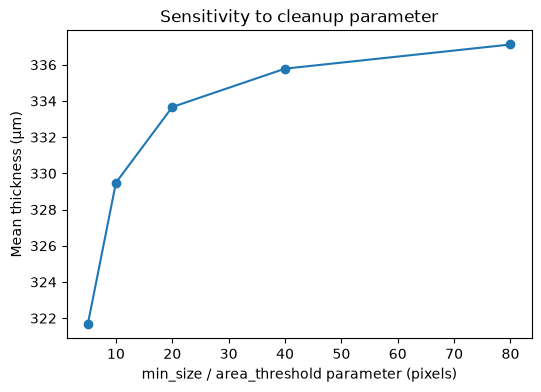

In [12]:
sizes_to_test = [5, 10, 20, 40, 80]
results_size = []

for s in sizes_to_test:
    t = measure_thickness(patch_cal, min_size=s, area_threshold=s)
    results_size.append(t.mean())
    print(f"min_size={s:3d}: mean thickness = {t.mean():.1f} µm  (n={len(t)} points)")

plt.figure(figsize=(6,4))
plt.plot(sizes_to_test, results_size, marker='o')
plt.xlabel("min_size / area_threshold parameter (pixels)")
plt.ylabel("Mean thickness (µm)")
plt.title("Sensitivity to cleanup parameter")
plt.show()

In [13]:
classes_to_test = [2, 3, 4]
results_classes = []

for c in classes_to_test:
    try:
        t = measure_thickness(patch_cal, n_classes=c)
        results_classes.append(t.mean())
        print(f"classes={c}: mean thickness = {t.mean():.1f} µm  (n={len(t)} points)")
    except Exception as e:
        print(f"classes={c}: failed ({e})")
        results_classes.append(np.nan)

/var/folders/gh/drjz5j_j7zb9cl9z206669bc0000gn/T/ipykernel_1396/2110472840.py:6: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  granular_clean = morphology.remove_small_objects(granular, min_size=min_size)
/var/folders/gh/drjz5j_j7zb9cl9z206669bc0000gn/T/ipykernel_1396/2110472840.py:7: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only re

classes=2: mean thickness = 348.8 µm  (n=10609 points)
classes=3: mean thickness = 333.7 µm  (n=10924 points)
classes=4: mean thickness = 318.0 µm  (n=11087 points)


/var/folders/gh/drjz5j_j7zb9cl9z206669bc0000gn/T/ipykernel_1396/2110472840.py:6: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  granular_clean = morphology.remove_small_objects(granular, min_size=min_size)
/var/folders/gh/drjz5j_j7zb9cl9z206669bc0000gn/T/ipykernel_1396/2110472840.py:7: FutureWarning: Parameter `area_threshold` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_holes`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only re

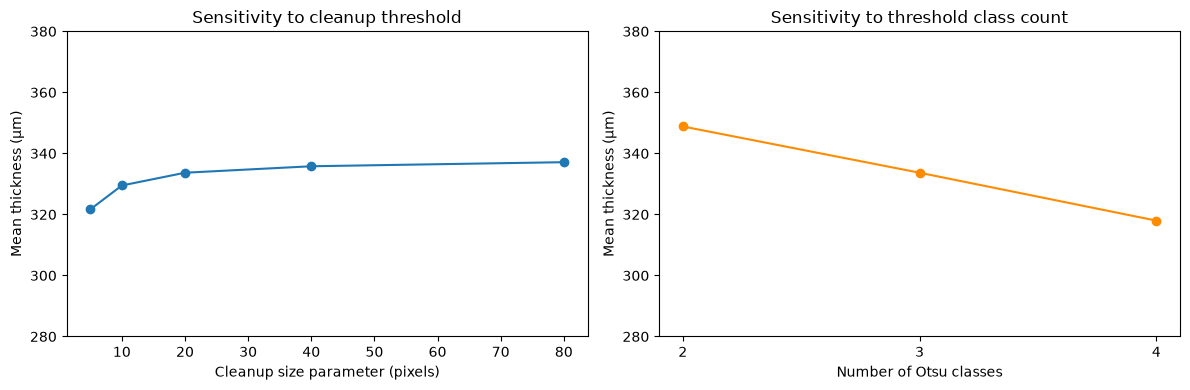

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))

axes[0].plot(sizes_to_test, results_size, marker='o')
axes[0].set_xlabel("Cleanup size parameter (pixels)")
axes[0].set_ylabel("Mean thickness (µm)")
axes[0].set_title("Sensitivity to cleanup threshold")
axes[0].set_ylim(280, 380)

axes[1].plot(classes_to_test, results_classes, marker='o', color='darkorange')
axes[1].set_xlabel("Number of Otsu classes")
axes[1].set_ylabel("Mean thickness (µm)")
axes[1].set_title("Sensitivity to threshold class count")
axes[1].set_xticks(classes_to_test)
axes[1].set_ylim(280, 380)

plt.tight_layout()
plt.savefig("sensitivity_analysis.png", dpi=150)
plt.show()

In [ ]:
Mean granular layer thickness stayed within roughly 300–350 µm across tested choices of cleanup threshold (5–80 px) and Otsu class count (2–4), a spread of under 10%, indicating the measurement is not highly sensitive to these pipeline parameters.